# Parent Fitness wird einfach übernommen!

In [6]:
import re

# Paste your log as a multi-line string
with open("run_12/shell_text.txt", "r") as f:
    log_data = f.read()


# Use regex to find all fitness values
fitness_values = [float(f) for f in re.findall(r"has fitness:\s+([0-9.]+)", log_data)]

print("Fitness values array:")
print(fitness_values)
print("Length: ", len(fitness_values))


Fitness values array:
[0.020000000000000004, 0.020000000000000004, 0.08, 1.15, 0.48, 0.009999999999999995, 0.03, 0.014999999999999986, 0.024999999999999994, 0.03, 0.1, 0.48, 0.07, 0.05, 0.015, 0.015, 0.07, 0.05, 0.009999999999999995, 0.03, 0.035, 0.06, 0.06, 0.7749999999999999, 0.009999999999999995, 0.035, 0.065, 0.07, 0.07, 0.5250000000000001, 0.07, 0.08, 0.07500000000000001, 0.42000000000000004, 0.05, 0.05499999999999999, 0.04500000000000001, 0.06, 0.039999999999999994, 0.06, 0.08, 0.08, 0.045, 0.06, 0.01999999999999999, 0.08, 0.08, 0.08, 0.10500000000000001, 0.1, 0.09, 0.1, 0.1, 0.10500000000000001, 0.1, 0.11000000000000001, 0.1, 0.05500000000000001, 0.085, 0.52, 0.025, 0.03, 0.8500000000000001, 0.08499999999999999, 0.065, 0.08499999999999999, 0.065, 3.2600000000000002, 0.05, 0.05, 0.0, 0.020000000000000004, 0.020000000000000004, 0.645, 0.085, 0.08, 0.08499999999999999, 0.06, 0.08, 0.06499999999999999, 0.08, 0.06, 0.06, 0.009999999999999995, 0.08, 0.045, 0.08, 0.03, 0.48, 0.0, 0.020

1200
1.1516291666666667 1.1974496301094695 0.0 4.699999999999999


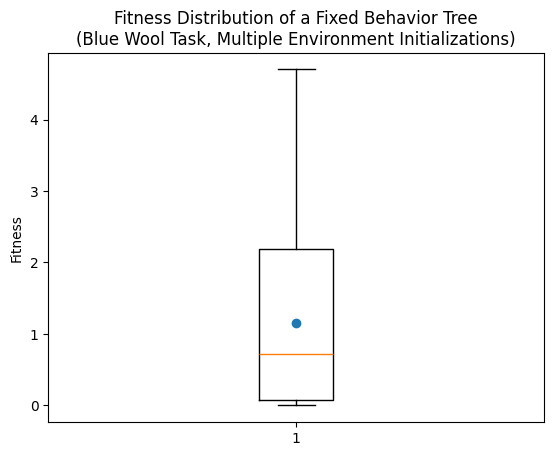

In [8]:
import matplotlib.pyplot as plt
import numpy as np

fitness = fitness_values[:1200]
t = len(fitness)
print(t)
mean_fitness = np.mean(fitness)
std_fitness = np.std(fitness)
min_fitness = np.min(fitness)
max_fitness = np.max(fitness)

print(mean_fitness, std_fitness, min_fitness, max_fitness)
plt.figure()
plt.boxplot(fitness, vert=True)
plt.scatter(1, mean_fitness)
plt.ylabel("Fitness")
plt.title("Fitness Distribution of a Fixed Behavior Tree\n(Blue Wool Task, Multiple Environment Initializations)")
plt.show()

In [1]:
import pickle
import matplotlib.pyplot as plt

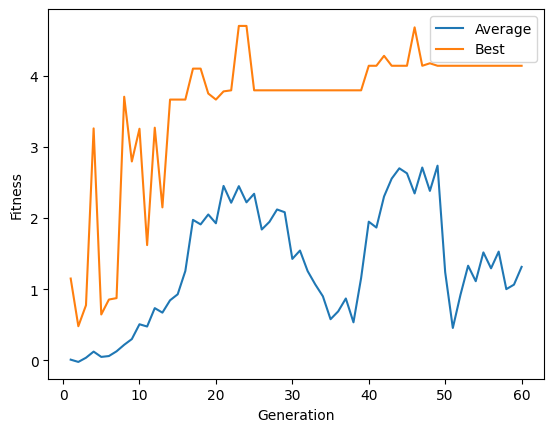

In [45]:
import pickle
import matplotlib.pyplot as plt
import os

# Path to folder containing generation pickle files
folder_path = "run_12/individuals"

# Get all pickle files in the folder
pickle_files = [f for f in os.listdir(folder_path) if f.endswith(".pkl")]

# Load data from each file
data = []
for file in pickle_files:
    with open(os.path.join(folder_path, file), "rb") as f:
        gen_data = pickle.load(f)
        data.append(gen_data)

# Sort data by generation
data.sort(key=lambda x: x['gen'])

# Extract generations, average fitness, and best fitness
gens = [d['gen'] for d in data]
avg_fitness = [sum(ind['fitness'] for ind in d['individuals']) / len(d['individuals']) for d in data]
best_fitness = [max(ind['fitness'] for ind in d['individuals']) for d in data]

# Plot
plt.plot(gens, avg_fitness, label="Average")
plt.plot(gens, best_fitness, label="Best")
plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.legend()
plt.show()


{'gen': 59,
 'individuals': [{'tree': 'sequence_2_child(Move, fallback_2_child(fallback_2_child(DigBlue, Look), fallback_2_child(DigBlue, Look)))',
   'fitness': 4.140000000000001},
  {'tree': 'sequence_2_child(Move, fallback_2_child(fallback_2_child(DigBlue, Look), fallback_2_child(DigBlue, Look)))',
   'fitness': 4.140000000000001},
  {'tree': 'sequence_2_child(Move, fallback_2_child(fallback_2_child(DigBlue, Look), fallback_2_child(DigBlue, Look)))',
   'fitness': 4.140000000000001},
  {'tree': 'sequence_2_child(fallback_2_child(Move, SenseOrange), Move)',
   'fitness': 0.06},
  {'tree': 'sequence_2_child(Move, fallback_2_child(fallback_2_child(DigBlue, Look), fallback_2_child(Look, Look)))',
   'fitness': -0.825},
  {'tree': 'sequence_2_child(Move, fallback_2_child(fallback_2_child(DigBlue, Look), fallback_2_child(fallback_2_child(DigOrange, fallback_2_child(SenseOrange, SenseBlue)), Look)))',
   'fitness': -0.845},
  {'tree': 'sequence_2_child(Move, DigBlue)', 'fitness': 0.08},
  

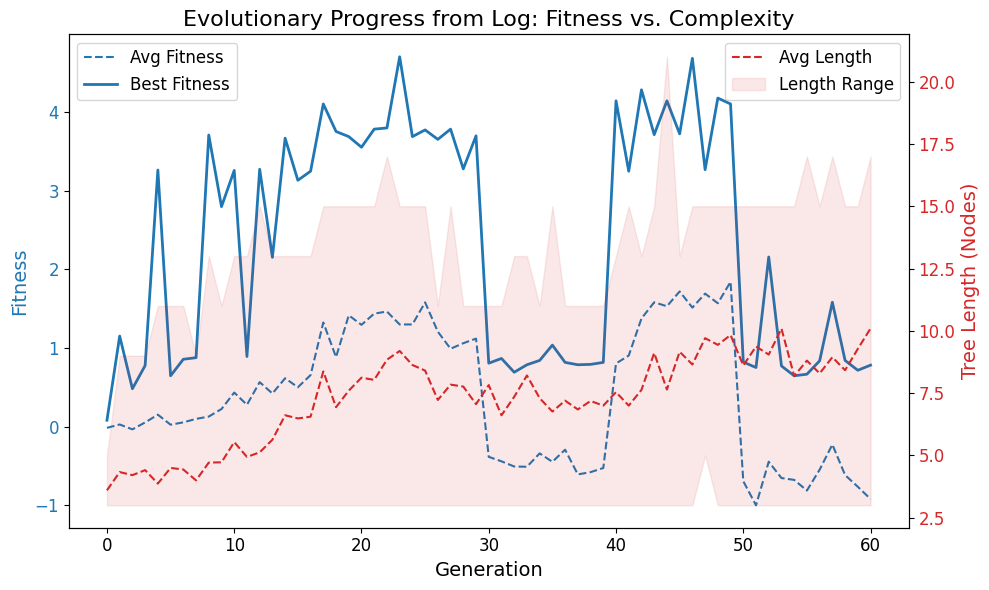

In [10]:
import re
from deap import gp
import numpy as np
import matplotlib.pyplot as plt

# --- Example: load text from file ---
with open("run_12/shell_text.txt", "r") as f:
    text = f.read()

# --- Generate PSet for parsing trees ---
def generate_pset():
    class WoolColor: pass
    class BehaviorTreeNode: pass
    class ActionNode(BehaviorTreeNode): pass

    pset = gp.PrimitiveSetTyped("MAIN", [], BehaviorTreeNode)

    # Branches
    pset.addPrimitive(sequence_1_child, [BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(sequence_2_child, [BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(sequence_3_child, [BehaviorTreeNode, BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(fallback_1_child, [BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(fallback_2_child, [BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(fallback_3_child, [BehaviorTreeNode, BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)

    # Functions for Dig/Sense (mocked)
    def make_dig(color): return None
    def make_sense(color): return None

    # Terminals
    pset.addPrimitive(make_dig, [WoolColor], ActionNode, name="Dig")
    pset.addPrimitive(make_sense, [WoolColor], ActionNode, name="CanDig")
    pset.addTerminal("blue_wool", WoolColor, name="BlueWool")
    pset.addTerminal("orange_wool", WoolColor, name="OrangeWool")
    pset.addTerminal(None, BehaviorTreeNode, name="DigBlue")
    pset.addTerminal(None, BehaviorTreeNode, name="DigOrange")
    pset.addTerminal(None, BehaviorTreeNode, name="Look")
    pset.addTerminal(None, BehaviorTreeNode, name="Move")
    pset.addTerminal(None, BehaviorTreeNode, name="Stop")
    pset.addTerminal(None, BehaviorTreeNode, name="SenseBlue")
    pset.addTerminal(None, BehaviorTreeNode, name="SenseOrange")

    return pset

pset = generate_pset()

# --- Parse the log text ---
generations = []
current_gen = None
individuals = []

for line in text.splitlines():
    # Start of a new generation
    gen_match = re.match(r"Run generation (\d+)/\d+", line)
    if gen_match:
        # Save previous generation
        if current_gen is not None:
            generations.append({'gen': current_gen, 'individuals': individuals})
        current_gen = int(gen_match.group(1))
        individuals = []
        continue

    # Parse tree and fitness
    tree_match = re.match(r"Tree:\s+(.*)\s+has fitness:\s+(-?\d+\.?\d*(?:[eE]-?\d+)?)", line)
    if tree_match:
        tree_str = tree_match.group(1).strip()
        fitness = float(tree_match.group(2))
        individuals.append({'tree': tree_str, 'fitness': fitness})

# Add last generation
if current_gen is not None:
    generations.append({'gen': current_gen, 'individuals': individuals})

# --- Compute statistics ---
gens = [d['gen'] for d in generations]
avg_fitness = [np.mean([ind['fitness'] for ind in d['individuals']]) for d in generations]
best_fitness = [np.max([ind['fitness'] for ind in d['individuals']]) for d in generations]

avg_length = []
max_length = []
min_length = []

for d in generations:
    lengths = [len(gp.PrimitiveTree.from_string(ind['tree'], pset)) for ind in d['individuals']]
    avg_length.append(np.mean(lengths))
    max_length.append(np.max(lengths))
    min_length.append(np.min(lengths))

# --- Plotting ---
fig, ax1 = plt.subplots(figsize=(10, 6))

# Fitness
ax1.set_xlabel("Generation", fontsize=14)
ax1.set_ylabel("Fitness", color="tab:blue", fontsize=14)
ax1.plot(gens, avg_fitness, label="Avg Fitness", color="tab:blue", linestyle="--")
ax1.plot(gens, best_fitness, label="Best Fitness", color="tab:blue", linewidth=2)
ax1.tick_params(axis='y', labelcolor="tab:blue", labelsize=12)
ax1.tick_params(axis='x', labelsize=12)

# Tree length
ax2 = ax1.twinx()
ax2.set_ylabel("Tree Length (Nodes)", color="tab:red", fontsize=14)
ax2.plot(gens, avg_length, label="Avg Length", color="tab:red", linestyle="--")
ax2.fill_between(gens, min_length, max_length, color="tab:red", alpha=0.1, label="Length Range")
ax2.tick_params(axis='y', labelcolor="tab:red", labelsize=12)

plt.title("Evolutionary Progress from Log: Fitness vs. Complexity", fontsize=16)
fig.tight_layout()
ax1.legend(loc="upper left", fontsize=12)
ax2.legend(loc="upper right", fontsize=12)

plt.show()



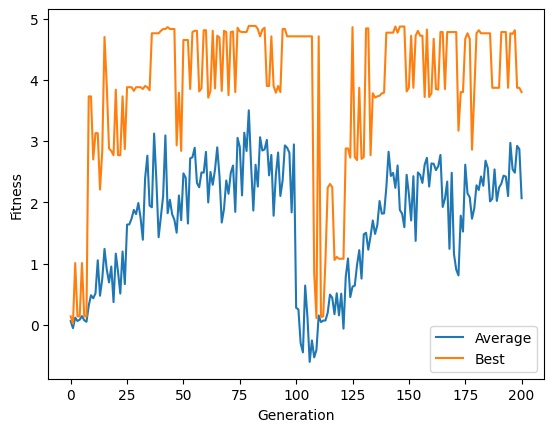

In [9]:

data = {}
with open(f"run_9/evolution_history.pkl", "rb") as f:
    data = pickle.load(f)

gens = [d['gen'] for d in data]
avg_fitness = [sum(ind['fitness'] for ind in d['individuals'])/len(d['individuals']) for d in data]
best_fitness = [max(ind['fitness'] for ind in d['individuals']) for d in data]

plt.plot(gens, avg_fitness, label="Average")
plt.plot(gens, best_fitness, label="Best")
plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.legend()
plt.show()

In [9]:
def sequence_1_child(child1):
    return SequenceNode([child1])

def sequence_2_child(child1, child2):
    return SequenceNode([child1, child2])

def sequence_3_child(child1, child2, child3):
    return SequenceNode([child1, child2, child3])

def fallback_1_child(child1):
    return FallbackNode([child1])

def fallback_2_child(child1, child2):
    return FallbackNode([child1, child2])

def fallback_3_child(child1, child2, child3):
    return FallbackNode([child1, child2, child3])

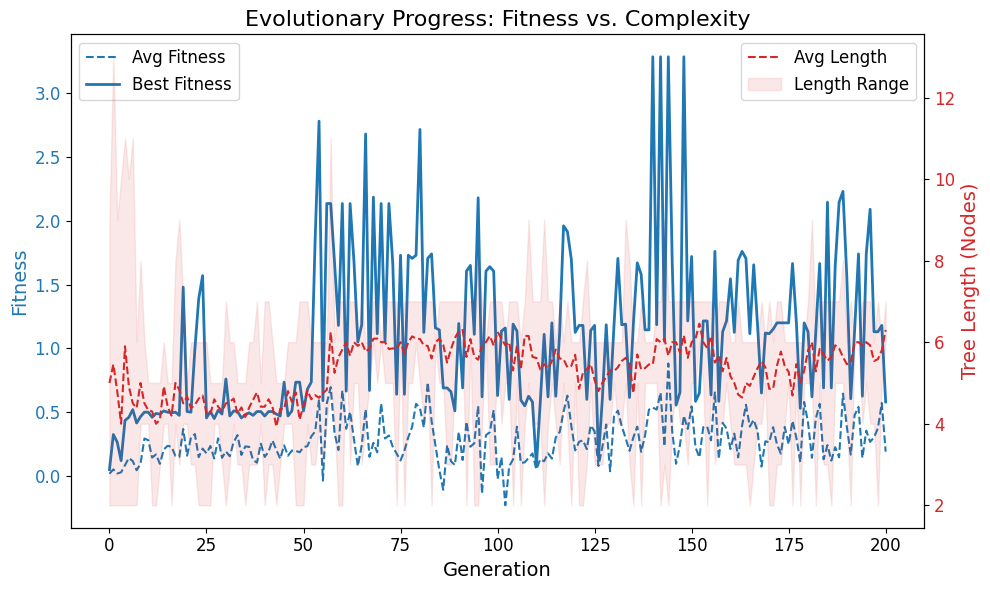

In [12]:
import pickle
import matplotlib.pyplot as plt
import numpy as np
from deap import gp

# Load data
with open("run_1/evolution_history.pkl", "rb") as f:
    data = pickle.load(f)

from collections import Counter

def clean_generations(data, start_gen=200, max_parents=5):
    """
    1. Removes up to `max_parents` exact (tree, fitness) matches carried
       over from the previous generation, prioritizing highest fitness.
    2. For generations 100–115 inclusive, removes all remaining individuals
       with fitness > 3.
    """

    # Ensure data is ordered by generation
    data = sorted(data, key=lambda d: d["gen"])
    gen_to_idx = {d["gen"]: i for i, d in enumerate(data)}

    for gen in range(start_gen, 0, -1):
        if gen not in gen_to_idx or (gen - 1) not in gen_to_idx:
            continue

        curr_entry = data[gen_to_idx[gen]]
        prev_entry = data[gen_to_idx[gen - 1]]

        curr_inds = curr_entry["individuals"]
        prev_inds = prev_entry["individuals"]

        # ---- Step 1: Perfect-match removal ----
        prev_pairs = Counter(
            (ind["tree"], ind["fitness"]) for ind in prev_inds
        )

        matches = []
        for idx, ind in enumerate(curr_inds):
            key = (ind["tree"], ind["fitness"])
            if prev_pairs.get(key, 0) > 0:
                matches.append((idx, ind))

        # Highest fitness removed first
        matches.sort(key=lambda x: x[1]["fitness"], reverse=True)

        remove_indices = set()
        removed = 0

        for idx, ind in matches:
            if removed >= max_parents:
                break
            key = (ind["tree"], ind["fitness"])
            if prev_pairs[key] > 0:
                prev_pairs[key] -= 1
                remove_indices.add(idx)
                removed += 1

        # Apply perfect-match removal
        curr_inds = [
            ind for i, ind in enumerate(curr_inds) if i not in remove_indices
        ]

        # ---- Step 2: Fitness threshold removal (gen 100–115) ----
        if 100 <= gen <= 115:
            curr_inds = [
                ind for ind in curr_inds if ind["fitness"] <= 1.5
            ]

        # Write back cleaned population
        curr_entry["individuals"] = curr_inds

    return data



data = clean_generations(data.copy())

def generate_pset():
    """
    Creates the Primitive Set (PSet) for DEAP.
    Nodes are mapped to 0-arity primitives (leaves) to handle arguments.
    Adjusted gp.generate to handle tree generation correctly. Missing prim and term raised errors.
    """
    class WoolColor(object):
        pass
    
    class BehaviorTreeNode(object):
        pass
    
    class ActionNode(BehaviorTreeNode):
        pass
    pset = gp.PrimitiveSetTyped("MAIN", [], BehaviorTreeNode)

    # Branches
    pset.addPrimitive(sequence_1_child, [BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(sequence_2_child, [BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(sequence_3_child, [BehaviorTreeNode, BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(fallback_1_child, [BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(fallback_2_child, [BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(fallback_3_child, [BehaviorTreeNode, BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)

    # functions for Dig
    def make_dig(color):
        return None
    def make_sense(color):
        return None
    
    
    # CHANGED
    # Primitives for Dig
    pset.addPrimitive(make_dig, [WoolColor], ActionNode, name="Dig")
    pset.addPrimitive(make_sense, [WoolColor], ActionNode, name="CanDig")
    # The wool color constants for Dig
    pset.addTerminal("blue_wool", WoolColor, name="BlueWool")
    pset.addTerminal("orange_wool", WoolColor, name="OrangeWool")

    ## CHANGED
    pset.addTerminal(None, BehaviorTreeNode, name="DigBlue") # Digs blue
    pset.addTerminal(None, BehaviorTreeNode, name="DigOrange") # Digs orange
    #set.addTerminal(StartDig(agents), ActionNode, name="Dig") # Digs everything
    pset.addTerminal(None, BehaviorTreeNode, name="Look")
    pset.addTerminal(None, BehaviorTreeNode, name="Move")
    pset.addTerminal(None, BehaviorTreeNode, name="Stop")
    pset.addTerminal(None, BehaviorTreeNode, name="SenseBlue") # Looks for blue
    pset.addTerminal(None, BehaviorTreeNode, name="SenseOrange") # Looks for orange
    #pset.addTerminal(CanDigBlock(agents), ActionNode, name="CanDig") # Looks for anything that can be dug

    return pset
# Recreate pset to parse strings (ensure all primitives are defined)
pset = generate_pset()

gens = []
avg_fitness = []
best_fitness = []
avg_length = []
max_length = []
min_length = []

for d in data:
    gens.append(d['gen'])

    # Fitness stats
    fits = [ind['fitness'] for ind in d['individuals']]
    avg_fitness.append(np.mean(fits))
    best_fitness.append(np.max(fits))

    # Length (Size) stats
    lengths = []
    for ind in d['individuals']:
        # Convert string to tree object to measure length
        tree = gp.PrimitiveTree.from_string(ind['tree'], pset)
        lengths.append(len(tree))

    avg_length.append(np.mean(lengths))
    max_length.append(np.max(lengths))
    min_length.append(np.min(lengths))

# --- Plotting ---
fig, ax1 = plt.subplots(figsize=(10, 6))

# Left Y-Axis: Fitness
ax1.set_xlabel("Generation", fontsize=14)
ax1.set_ylabel("Fitness", color="tab:blue", fontsize=14)
ax1.plot(gens, avg_fitness, label="Avg Fitness", color="tab:blue", linestyle="--")
ax1.plot(gens, best_fitness, label="Best Fitness", color="tab:blue", linewidth=2)
ax1.tick_params(axis='y', labelcolor="tab:blue", labelsize=12)
ax1.tick_params(axis='x', labelsize=12)

# Right Y-Axis: Tree Length
ax2 = ax1.twinx()
ax2.set_ylabel("Tree Length (Nodes)", color="tab:red", fontsize=14)
ax2.plot(gens, avg_length, label="Avg Length", color="tab:red", linestyle="--")
ax2.fill_between(gens, min_length, max_length, color="tab:red", alpha=0.1, label="Length Range")
ax2.tick_params(axis='y', labelcolor="tab:red", labelsize=12)

plt.title("Evolutionary Progress: Fitness vs. Complexity", fontsize=16)
fig.tight_layout()
ax1.legend(loc="upper left", fontsize=12)
ax2.legend(loc="upper right", fontsize=12)

plt.show()


In [4]:
import pickle
import copy
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from deap import gp


# =========================
# Load evolutionary history
# =========================
with open("run_13/evolution_history.pkl", "rb") as f:
    data = pickle.load(f)


# =========================
# Cleaning logic
# =========================
def clean_generations(data, start_gen=200, max_parents=5):
    """
    1. Removes up to `max_parents` exact (tree, fitness) matches carried
       over from the previous generation, prioritizing highest fitness.
    2. For generations 100–115 inclusive, removes all remaining individuals
       with fitness > 3.
    """

    data = sorted(data, key=lambda d: d["gen"])
    gen_to_idx = {d["gen"]: i for i, d in enumerate(data)}

    for gen in range(start_gen, 0, -1):
        if gen not in gen_to_idx or (gen - 1) not in gen_to_idx:
            continue

        curr_entry = data[gen_to_idx[gen]]
        prev_entry = data[gen_to_idx[gen - 1]]

        curr_inds = curr_entry["individuals"]
        prev_inds = prev_entry["individuals"]

        # ---- Step 1: perfect-match removal ----
        prev_pairs = Counter(
            (ind["tree"], ind["fitness"]) for ind in prev_inds
        )

        matches = []
        for idx, ind in enumerate(curr_inds):
            key = (ind["tree"], ind["fitness"])
            if prev_pairs.get(key, 0) > 0:
                matches.append((idx, ind))

        # Remove highest fitness first
        matches.sort(key=lambda x: x[1]["fitness"], reverse=True)

        remove_indices = set()
        removed = 0

        for idx, ind in matches:
            if removed >= max_parents:
                break
            key = (ind["tree"], ind["fitness"])
            if prev_pairs[key] > 0:
                prev_pairs[key] -= 1
                remove_indices.add(idx)
                removed += 1

        curr_inds = [
            ind for i, ind in enumerate(curr_inds)
            if i not in remove_indices
        ]

        # ---- Step 2: fitness threshold (gens 100–115) ----
        if 100 <= gen <= 115:
            curr_inds = [
                ind for ind in curr_inds if ind["fitness"] <= 3
            ]

        curr_entry["individuals"] = curr_inds

    return data


# Preserve original data
data_clean = clean_generations(copy.deepcopy(data))


# =========================
# Primitive set definition
# =========================
def generate_pset():
    class WoolColor:
        pass

    class BehaviorTreeNode:
        pass

    class ActionNode(BehaviorTreeNode):
        pass

    pset = gp.PrimitiveSetTyped("MAIN", [], BehaviorTreeNode)

    # Control flow
    pset.addPrimitive(sequence_1_child, [BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(sequence_2_child, [BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(sequence_3_child, [BehaviorTreeNode, BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(fallback_1_child, [BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(fallback_2_child, [BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(fallback_3_child, [BehaviorTreeNode, BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)

    # Action constructors
    def make_dig(color):
        return None

    def make_sense(color):
        return None

    pset.addPrimitive(make_dig, [WoolColor], ActionNode, name="Dig")
    pset.addPrimitive(make_sense, [WoolColor], ActionNode, name="CanDig")

    pset.addTerminal("blue_wool", WoolColor, name="BlueWool")
    pset.addTerminal("orange_wool", WoolColor, name="OrangeWool")

    # Leaf actions
    pset.addTerminal(None, BehaviorTreeNode, name="DigBlue")
    pset.addTerminal(None, BehaviorTreeNode, name="DigOrange")
    pset.addTerminal(None, BehaviorTreeNode, name="Look")
    pset.addTerminal(None, BehaviorTreeNode, name="Move")
    pset.addTerminal(None, BehaviorTreeNode, name="Stop")
    pset.addTerminal(None, BehaviorTreeNode, name="SenseBlue")
    pset.addTerminal(None, BehaviorTreeNode, name="SenseOrange")

    return pset


pset = generate_pset()


# =========================
# Statistics computation
# =========================
def compute_stats(data, pset):
    gens = []
    avg_fitness = []
    best_fitness = []
    avg_length = []
    max_length = []
    min_length = []

    for d in data:
        gens.append(d["gen"])

        fits = [ind["fitness"] for ind in d["individuals"]]
        avg_fitness.append(np.mean(fits))
        best_fitness.append(np.max(fits))

        lengths = []
        for ind in d["individuals"]:
            tree = gp.PrimitiveTree.from_string(ind["tree"], pset)
            lengths.append(len(tree))

        avg_length.append(np.mean(lengths))
        max_length.append(np.max(lengths))
        min_length.append(np.min(lengths))

    return {
        "gens": gens,
        "avg_fitness": avg_fitness,
        "best_fitness": best_fitness,
        "avg_length": avg_length,
        "max_length": max_length,
        "min_length": min_length,
    }


stats_orig = compute_stats(data, pset)
stats_clean = compute_stats(data_clean, pset)


# =========================
# Plot: original vs cleaned
# =========================
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.set_xlabel("Generation")
ax1.set_ylabel("Fitness")

ax1.plot(
    stats_orig["gens"],
    stats_orig["avg_fitness"],
    linestyle="--",
    label="Avg Fitness (Original)"
)
ax1.plot(
    stats_orig["gens"],
    stats_orig["best_fitness"],
    linewidth=2,
    label="Best Fitness (Original)"
)

ax1.plot(
    stats_clean["gens"],
    stats_clean["avg_fitness"],
    linestyle="--",
    label="Avg Fitness (Cleaned)"
)
ax1.plot(
    stats_clean["gens"],
    stats_clean["best_fitness"],
    linewidth=2,
    label="Best Fitness (Cleaned)"
)

ax2 = ax1.twinx()
ax2.set_ylabel("Tree Length (Nodes)")

ax2.plot(
    stats_orig["gens"],
    stats_orig["avg_length"],
    linestyle=":",
    label="Avg Length (Original)"
)
ax2.plot(
    stats_clean["gens"],
    stats_clean["avg_length"],
    linestyle=":",
    label="Avg Length (Cleaned)"
)

ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

plt.title("Evolutionary Progress: Original vs. Cleaned Populations")
fig.tight_layout()
plt.show()


/home/ben/PycharmProjects/swarmcraft/.venv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/ben/PycharmProjects/swarmcraft/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


ValueError: zero-size array to reduction operation maximum which has no identity

In [5]:
data = []
for i in range(3):
    with open(f"run_9/snapshots/top5_gen_{i}.pkl", "rb") as f:
        data += pickle.load(f)

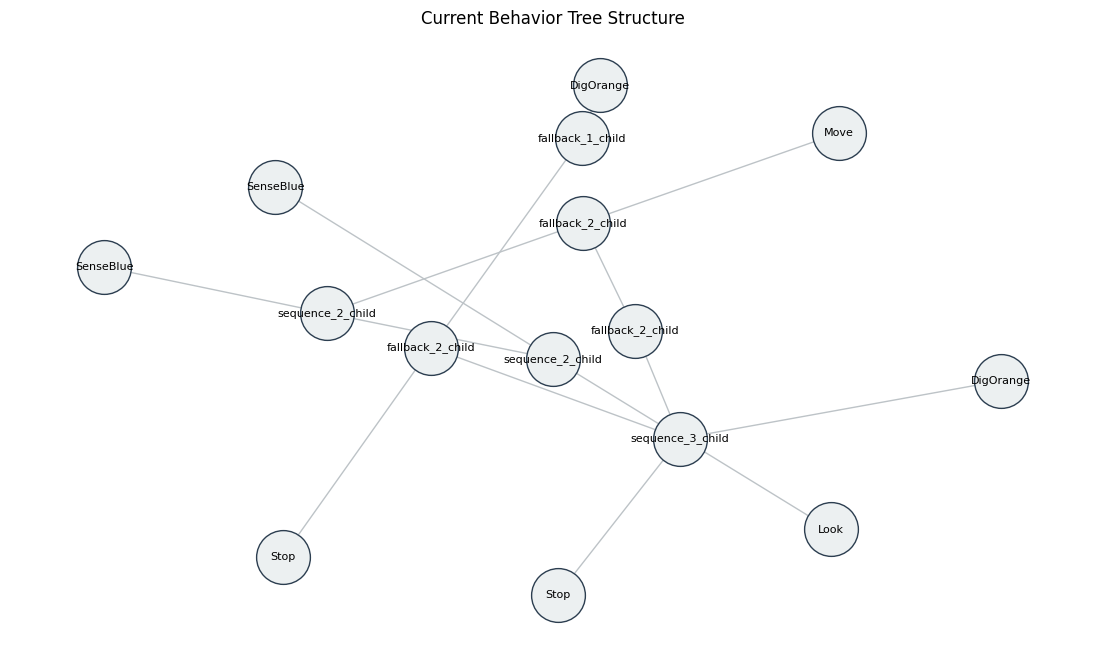

In [1]:
import pickle
import matplotlib.pyplot as plt
import networkx as nx
from deap import gp

class BehaviorTreeNode(object):
    def __init__(self):
        pass
class SequenceNode(object):
    def __init__(self):
        pass
class FallbackNode(object):
    def __init__(self):
        pass
def sequence_1_child(child1):
    return SequenceNode([child1])

def sequence_2_child(child1, child2):
    return SequenceNode([child1, child2])

def sequence_3_child(child1, child2, child3):
    return SequenceNode([child1, child2, child3])

def fallback_1_child(child1):
    return FallbackNode([child1])

def fallback_2_child(child1, child2):
    return FallbackNode([child1, child2])

def fallback_3_child(child1, child2, child3):
    return FallbackNode([child1, child2, child3])
# Ensure the pset has all nodes found in your string
def generate_visualization_pset():
    pset = gp.PrimitiveSetTyped("MAIN", [], BehaviorTreeNode)
    # Control Nodes
    pset.addPrimitive(sequence_1_child, [BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(sequence_2_child, [BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(sequence_3_child, [BehaviorTreeNode, BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(fallback_1_child, [BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(fallback_2_child, [BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)

    # Terminals (Leaves) - Names must match the string exactly
    pset.addTerminal(None, BehaviorTreeNode, name="DigBlue")
    pset.addTerminal(None, BehaviorTreeNode, name="DigOrange")
    pset.addTerminal(None, BehaviorTreeNode, name="Look")
    pset.addTerminal(None, BehaviorTreeNode, name="Move")
    pset.addTerminal(None, BehaviorTreeNode, name="Stop")
    pset.addTerminal(None, BehaviorTreeNode, name="SenseBlue")
    pset.addTerminal(None, BehaviorTreeNode, name="SenseOrange")
    return pset


def plot_tree_from_dict(data_dict):
    pset = generate_visualization_pset()
    tree_str = data_dict['tree']

    # Reconstruct Tree
    tree = gp.PrimitiveTree.from_string(tree_str, pset)
    nodes, edges, labels = gp.graph(tree)

    # Graph Setup
    g = nx.DiGraph()
    g.add_nodes_from(nodes)
    g.add_edges_from(edges)

    # Attempt hierarchical layout
    try:
        from networkx.drawing.nx_agraph import graphviz_layout
        pos = graphviz_layout(g, prog="dot")
    except ImportError:
        pos = nx.spring_layout(g) # Fallback

    plt.figure(figsize=(14, 8))
    nx.draw_networkx_nodes(g, pos, node_size=1500, node_color="#ecf0f1", edgecolors="#2c3e50")
    nx.draw_networkx_edges(g, pos, arrows=True, edge_color="#bdc3c7")
    nx.draw_networkx_labels(g, pos, labels, font_size=8)

    plt.title("Current Behavior Tree Structure")
    plt.axis("off")
    plt.show()

# Example Data Execution
data = {'tree': 'fallback_2_child(fallback_2_child(Move, sequence_2_child(sequence_2_child(SenseBlue, Look), SenseBlue)), sequence_3_child(fallback_2_child(fallback_1_child(DigOrange), Stop), DigOrange, Stop))'}
plot_tree_from_dict(data)

In [14]:
class BehaviorTreeNode(object):
    def __init__(self):
        pass
class SequenceNode(object):
    def __init__(self):
        pass
class FallbackNode(object):
    def __init__(self):
        pass
def sequence_1_child(child1):
    return SequenceNode([child1])

def sequence_2_child(child1, child2):
    return SequenceNode([child1, child2])

def sequence_3_child(child1, child2, child3):
    return SequenceNode([child1, child2, child3])

def fallback_1_child(child1):
    return FallbackNode([child1])

def fallback_2_child(child1, child2):
    return FallbackNode([child1, child2])

def fallback_3_child(child1, child2, child3):
    return FallbackNode([child1, child2, child3])

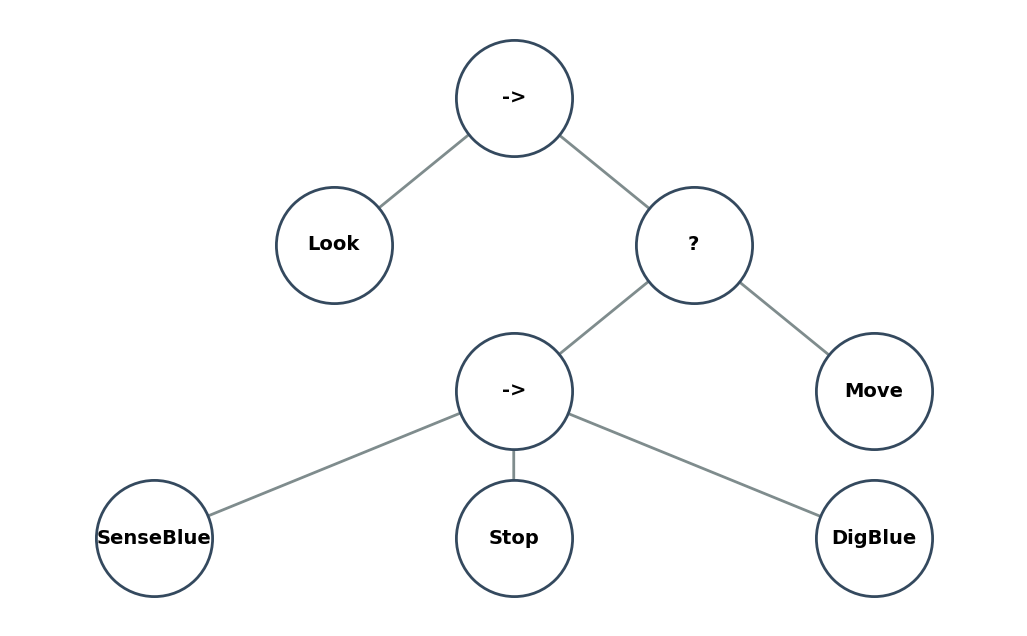

In [24]:
import pickle
import matplotlib.pyplot as plt
import networkx as nx
from deap import gp
import pygraphviz as pgv # Required for 'dot' layout

def generate_pset():
    pset = gp.PrimitiveSetTyped("MAIN", [], BehaviorTreeNode)
    # Control Nodes
    pset.addPrimitive(sequence_1_child, [BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(sequence_2_child, [BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(sequence_3_child, [BehaviorTreeNode, BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(fallback_1_child, [BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(fallback_2_child, [BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)
    pset.addPrimitive(fallback_3_child, [BehaviorTreeNode, BehaviorTreeNode, BehaviorTreeNode], BehaviorTreeNode)

    # Terminals (Leaves) - Names must match the string exactly
    pset.addTerminal(None, BehaviorTreeNode, name="DigBlue")
    pset.addTerminal(None, BehaviorTreeNode, name="DigOrange")
    pset.addTerminal(None, BehaviorTreeNode, name="Look")
    pset.addTerminal(None, BehaviorTreeNode, name="Move")
    pset.addTerminal(None, BehaviorTreeNode, name="Stop")
    pset.addTerminal(None, BehaviorTreeNode, name="SenseBlue")
    pset.addTerminal(None, BehaviorTreeNode, name="SenseOrange")
    return pset



def visualize_bt_with_symbols(tree_dict, pset):
    tree_str = tree_dict['tree']

    # 1. Reconstruct the tree
    tree = gp.PrimitiveTree.from_string(tree_str, pset)
    nodes, edges, labels = gp.graph(tree)

    # 2. Define the Symbol Mapping
    symbol_map = {
        "sequence_1_child": "->",
        "sequence_2_child": "->",
        "sequence_3_child": "->",
        "fallback_1_child": "?",
        "fallback_2_child": "?",
        "fallback_3_child": "?",
    }

    # 3. Substitute the labels
    clean_labels = {node_index: symbol_map.get(name, name) for node_index, name in labels.items()}

    # 4. Create Graph and Layout
    g = nx.DiGraph()
    g.add_nodes_from(nodes)
    g.add_edges_from(edges)

    # Use 'dot' layout with reduced spacing
    pos = nx.nx_agraph.graphviz_layout(g, prog="dot", args='-Gnodesep=0.5 -Granksep=0.7')

    # 5. Drawing
    plt.figure(figsize=(13, 8))

    # Draw nodes (larger)
    nx.draw_networkx_nodes(
        g, pos,
        node_size=7000,          # bigger nodes
        node_color="#ffffff",
        edgecolors="#34495e",
        linewidths=2
    )

    # Draw edges (arrows)
    nx.draw_networkx_edges(
        g, pos,
        arrows=True,
        arrowsize=20,
        edge_color="#7f8c8d",
        width=2
    )

    # Draw labels
    nx.draw_networkx_labels(
        g, pos, clean_labels,
        font_size=14,
        font_weight="bold"
    )

    # Turn off axes
    plt.axis("off")

    # --- Fix cutting off nodes by expanding limits ---
    x_values, y_values = zip(*pos.values())
    x_margin = (max(x_values) - min(x_values)) * 0.2  # 10% margin
    y_margin = (max(y_values) - min(y_values)) * 0.2
    plt.xlim(min(x_values) - x_margin, max(x_values) + x_margin)
    plt.ylim(min(y_values) - y_margin, max(y_values) + y_margin)

    plt.show()



# --- Example Usage ---
# Ensure your pset has all nodes used in the string
pset = generate_pset()
data = {'tree': 'fallback_2_child(fallback_2_child(Move, sequence_2_child(sequence_2_child(SenseBlue, Look), SenseBlue)), sequence_3_child(fallback_2_child(fallback_1_child(DigOrange), Stop), DigOrange, Stop))'}
data = {'tree': 'sequence_2_child(Look, fallback_2_child(sequence_3_child(SenseBlue, Stop, DigBlue), Move)'}

visualize_bt_with_symbols(data, pset)

In [57]:
data[100:105]


[{'gen': 100,
  'individuals': [{'tree': 'sequence_1_child(sequence_3_child(sequence_3_child(Move, Look, DigBlue), fallback_3_child(SenseBlue, fallback_3_child(SenseOrange, Look, fallback_3_child(SenseOrange, SenseOrange, Move)), Stop), sequence_2_child(sequence_3_child(Look, DigBlue, sequence_1_child(Move)), sequence_3_child(DigBlue, sequence_3_child(Stop, DigBlue, Look), sequence_2_child(sequence_3_child(fallback_3_child(Move, sequence_2_child(DigOrange, SenseBlue), sequence_1_child(SenseOrange)), fallback_2_child(DigBlue, sequence_3_child(Stop, sequence_3_child(DigBlue, SenseBlue, SenseBlue), SenseBlue)), SenseBlue), sequence_3_child(DigBlue, SenseBlue, Stop))))))',
    'fitness': -2.26},
   {'tree': 'sequence_1_child(sequence_3_child(fallback_3_child(sequence_3_child(DigOrange, DigBlue, SenseBlue), SenseBlue, sequence_2_child(SenseBlue, SenseOrange)), fallback_3_child(SenseBlue, fallback_3_child(SenseOrange, Look, fallback_3_child(SenseOrange, SenseOrange, Move)), Stop), sequence_2

In [27]:
for d in data[130:150]:
    print("-"*40)
    t = d['individuals']
    #e = t['fitness']
    print(d['gen'], " \n" , t[0]['fitness'])

----------------------------------------
130  
 1.18
----------------------------------------
131  
 0.01
----------------------------------------
132  
 1.705
----------------------------------------
133  
 0.08
----------------------------------------
134  
 0.11
----------------------------------------
135  
 0.01
----------------------------------------
136  
 0.05
----------------------------------------
137  
 0.04
----------------------------------------
138  
 0.645
----------------------------------------
139  
 0.11
----------------------------------------
140  
 1.1849999999999998
----------------------------------------
141  
 0.11499999999999999
----------------------------------------
142  
 0.05
----------------------------------------
143  
 3.285
----------------------------------------
144  
 3.285
----------------------------------------
145  
 0.5900000000000001
----------------------------------------
146  
 0.01
----------------------------------------
147  
 0.06

In [28]:
len(data[99])
data[112]

{'gen': 112,
 'individuals': [{'tree': 'fallback_3_child(Move, Move, SenseBlue)',
   'fitness': 0.13},
  {'tree': 'fallback_1_child(Move)', 'fitness': 0.13},
  {'tree': 'fallback_1_child(DigBlue)', 'fitness': 0.01},
  {'tree': 'fallback_1_child(DigBlue)', 'fitness': 0.01},
  {'tree': 'fallback_1_child(fallback_3_child(DigOrange, Look, DigOrange))',
   'fitness': 0.01},
  {'tree': 'fallback_1_child(Move)', 'fitness': 0.07},
  {'tree': 'fallback_1_child(Move)', 'fitness': 0.14},
  {'tree': 'fallback_1_child(sequence_1_child(SenseOrange))', 'fitness': 0.01},
  {'tree': 'fallback_1_child(Move)', 'fitness': 0.13},
  {'tree': 'fallback_1_child(fallback_2_child(Look, Stop))', 'fitness': 0.01},
  {'tree': 'fallback_1_child(Move)', 'fitness': 0.07},
  {'tree': 'fallback_1_child(fallback_3_child(DigOrange, Move, Move))',
   'fitness': 0.11},
  {'tree': 'fallback_1_child(Move)', 'fitness': 0.11},
  {'tree': 'fallback_1_child(fallback_1_child(SenseBlue))', 'fitness': 0.01},
  {'tree': 'fallback_1_

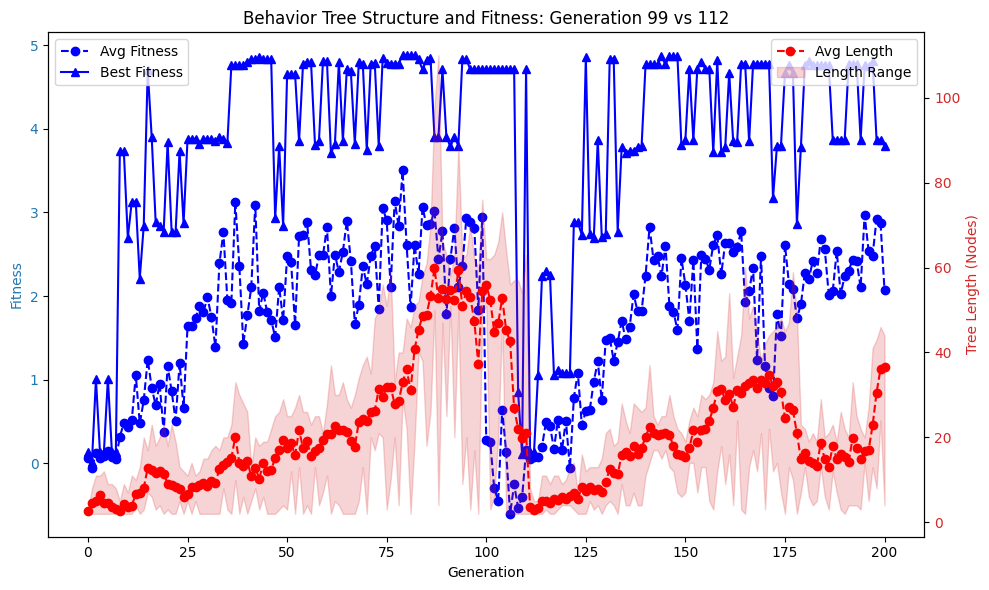

In [31]:
import matplotlib.pyplot as plt
import numpy as np
from deap import gp  # Assuming you are using DEAP for tree parsing




# --- Parse data ---
gens = []
avg_fitness = []
best_fitness = []
avg_length = []
min_length = []
max_length = []

for d in data:
    gens.append(d['gen'])

    # Fitness
    fits = [ind['fitness'] for ind in d['individuals']]
    avg_fitness.append(np.mean(fits))
    best_fitness.append(np.max(fits))

    # Tree length
    lengths = []
    for ind in d['individuals']:
        try:
            tree = gp.PrimitiveTree.from_string(ind['tree'], pset)
            lengths.append(len(tree))
        except Exception as e:
            # If parsing fails, fallback to counting parentheses as proxy
            lengths.append(ind['tree'].count('('))
    avg_length.append(np.mean(lengths))
    min_length.append(np.min(lengths))
    max_length.append(np.max(lengths))

# --- Plotting ---
fig, ax1 = plt.subplots(figsize=(10,6))

# Fitness (left axis)
ax1.set_xlabel("Generation")
ax1.set_ylabel("Fitness", color="tab:blue")
ax1.plot(gens, avg_fitness, 'bo--', label="Avg Fitness")
ax1.plot(gens, best_fitness, 'b^-', label="Best Fitness")
ax1.tick_params(axis='y', labelcolor="tab:blue")

# Tree length (right axis)
ax2 = ax1.twinx()
ax2.set_ylabel("Tree Length (Nodes)", color="tab:red")
ax2.plot(gens, avg_length, 'ro--', label="Avg Length")
ax2.fill_between(gens, min_length, max_length, color="tab:red", alpha=0.2, label="Length Range")
ax2.tick_params(axis='y', labelcolor="tab:red")

plt.title("Behavior Tree Structure and Fitness: Generation 99 vs 112")
fig.tight_layout()
ax1.legend(loc="upper left")
ax2.legend(loc="upper right")
plt.show()


In [3]:
with open("run_0/hof_history.pkl", "rb") as f:
    data2 = pickle.load(f)
data2

[{'gen': 0,
  'hof': [{'tree': 'fallback_3_child(Move, fallback_3_child(Look, Move, Move), fallback_3_child(Look, Stop, Look))',
    'fitness': 0.12},
   {'tree': 'fallback_2_child(Stop, Move)', 'fitness': 0.01}]},
 {'gen': 1,
  'hof': [{'tree': 'sequence_3_child(Move, Look, Look)', 'fitness': 0.38},
   {'tree': 'fallback_3_child(Move, fallback_3_child(Look, Move, Move), fallback_3_child(Look, Stop, Look))',
    'fitness': 0.12},
   {'tree': 'fallback_2_child(Stop, Move)', 'fitness': 0.01}]},
 {'gen': 2,
  'hof': [{'tree': 'sequence_3_child(Move, Look, CanDig(BlueWool))',
    'fitness': 0.49},
   {'tree': 'sequence_3_child(Move, Look, Look)', 'fitness': 0.38},
   {'tree': 'sequence_3_child(Move, CanDig(OrangeWool), Look)',
    'fitness': 0.17},
   {'tree': 'fallback_3_child(Move, fallback_3_child(Look, Move, Move), fallback_3_child(Look, Stop, Look))',
    'fitness': 0.12},
   {'tree': 'fallback_2_child(Stop, Move)', 'fitness': 0.01}]}]